# Data pre-processing and correlation analysis

In [189]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, spearmanr

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from pathlib import Path
# Ensure the 'data' directory exists
data_dir = Path.cwd() / "data"
data_dir.mkdir(parents=True, exist_ok=True)
mods = {"pandas": pd, "numpy": np, "matplotlib": sys.modules.get("matplotlib"),
        "scikit-learn": sys.modules.get("sklearn"), "joblib": sys.modules.get("joblib"),
        "standardised_pipeline_utils": sys.modules.get("standardised_pipeline_utils")}
print(f"{'python':<28} {sys.version.split()[0]}")
for n, m in mods.items(): print(f"{n:<28} {getattr(m, '__version__', '(no __version__)') if m else 'not loaded'}")


python                       3.11.5
pandas                       2.3.2
numpy                        1.24.4
matplotlib                   3.7.2
scikit-learn                 1.7.2
joblib                       1.2.0
standardised_pipeline_utils  (no __version__)


#### Datasets Used:
 
CCLE genes expressions:
Proteomics:

In [190]:
transcriptomics = load(data_dir/"transcriptomics_filtered.joblib")
proteomics = load(data_dir / "proteomics_matched.joblib")
pearson = load(data_dir / "full_pearson100.joblib")

print(transcriptomics.shape)
print(proteomics.shape)

(375, 22614)
(375, 5113)


In [191]:
# Take 10 samples for prot_test (reproducible)
n_test = 25
prot_test = proteomics.sample(n=min(n_test, len(proteomics)), random_state=42).copy()

# Keep the remaining samples as proteomics
proteomics = proteomics.drop(index=prot_test.index).copy()
transcriptomics_test = transcriptomics.loc[prot_test.index].copy()
transcriptomics = transcriptomics.drop(index=prot_test.index).copy()
print(proteomics.shape)
print(transcriptomics.shape)

(350, 5113)
(350, 22614)


In [192]:
proteomics

proteins,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS,AARS2,...,ZNF787,ZNF800,ZNF830,ZNHIT6,ZNRD1,ZRANB2,ZW10,ZWILCH,ZYX,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
SH4_SKIN,1.642186,-0.283335,0.162102,-0.057517,0.760639,0.119699,0.105279,-0.075316,0.399385,1.102265,...,-0.248390,0.531159,-0.452978,-0.386262,-0.047313,-0.499179,-0.208351,-0.163901,-0.361225,-0.371537
AU565_BREAST,-1.129114,0.024663,1.071283,-0.758048,-0.320451,-1.068118,-0.158266,0.365150,-0.797109,-0.272314,...,0.043493,1.607322,-0.547892,-0.175286,0.061356,-0.175592,0.071945,-0.393799,0.309026,-0.301741
KMRC1_KIDNEY,1.493333,-0.588886,0.404605,-0.210457,0.533949,0.437453,-0.070486,-0.045454,0.048472,-0.352636,...,-0.226766,-0.363713,0.001180,-0.517588,-0.286447,-0.326172,0.019450,-0.055173,0.574568,-0.732279
CAL51_BREAST,0.274652,0.673324,-0.587890,-0.044001,-0.778679,0.051707,0.294878,-0.211209,-0.436950,0.113565,...,0.319720,-0.184053,0.322673,-0.294126,0.161771,-0.060968,0.103745,0.151656,-0.218916,0.697868
RPMI7951_SKIN,-0.615667,0.010466,0.025699,0.381038,0.333378,0.195878,0.060795,0.173234,-0.215418,-0.395577,...,-0.053318,-0.564690,0.174517,0.055248,0.157134,-0.280411,0.055301,0.167905,0.349964,0.166516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,-1.116991,-0.779655,-0.343373,0.032533,-1.433436,-0.991085,-0.899321,-0.620034,-0.625103,-0.697012,...,0.821462,0.343556,0.993749,-0.348426,1.067482,0.125648,-0.894195,-0.610845,-0.306374,-0.005547
KP4_PANCREAS,1.922976,-0.628770,-1.200965,2.101721,-0.549493,1.602728,0.949461,-0.512347,-0.856384,-0.896097,...,-0.473678,-0.024037,1.098143,0.337931,1.372841,-0.052092,-0.519440,-0.873276,1.281937,1.008579
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-1.106344,1.205109,0.660346,-0.539838,0.951283,0.139173,-0.211486,0.418099,-0.894781,0.713249,...,0.271313,0.084621,0.244403,0.347557,0.136414,0.282679,0.672338,0.885732,-0.498927,-0.157715


### Correlations

In [193]:
# Find matched samples with samples and proteins with genes
transcriptomics_corr, proteomics_corr = standardised_pipeline_utils.match_proteins_samples(transcriptomics.T,
                                                                                           proteomics.T)

Number of common proteins:  4843
Number of common samples:  350


#### Pearson 

In [194]:
# Pearson correlation on 4843 features
pearson_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='pearson')
# Descriptive statistics on pearson correlation
pearson_correlations.describe()

count    4843.000000
mean        0.465597
std         0.215364
min        -0.179304
25%         0.312368
50%         0.472185
75%         0.629994
max         0.906462
dtype: float64

In [195]:
pe85_set = set(pearson_correlations[pearson_correlations > 0.85].index)
pe85 = list(pearson_correlations[pearson_correlations > 0.85].index)
pe85.sort(reverse=True)
print(len(pe85))


53


In [196]:
pe85

['VIM',
 'VIL1',
 'TRIP6',
 'TJP2',
 'TGM2',
 'ST14',
 'SPATS2L',
 'SLC16A3',
 'SERPINH1',
 'SERPINB5',
 'SELENBP1',
 'RBM47',
 'PTK7',
 'PSMB8',
 'PDLIM4',
 'PDLIM1',
 'PAPSS2',
 'NT5E',
 'MYO1D',
 'MCAM',
 'MAP1B',
 'MAGEA4',
 'LGALS1',
 'LCP1',
 'LAD1',
 'ITGB3',
 'ITGA2',
 'IGF2BP1',
 'IFI16',
 'HSPA2',
 'HCLS1',
 'GPX8',
 'GNG12',
 'GDA',
 'FHL2',
 'ERBB2',
 'EPCAM',
 'EGFR',
 'DPYSL3',
 'DCBLD2',
 'DAB2',
 'CORO1A',
 'CKAP4',
 'CDH2',
 'CDH1',
 'CDCP1',
 'CD44',
 'CA2',
 'BASP1',
 'ANPEP',
 'ALDH2',
 'ALDH1A3',
 'ALDH1A1']

In [197]:
pearson_correlations['UCHL1']

0.8470938253115596

In [198]:
pe75 = set(pearson_correlations[pearson_correlations > 0.75].index)
len(pe75)

534

#### Spearman

In [199]:
# Spearman correlation on 4843 features

spearman_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='spearman')
# Descriptive statistics on spearman correlation
spearman_correlations.describe()

count    4843.000000
mean        0.446140
std         0.209393
min        -0.175456
25%         0.297915
50%         0.452880
75%         0.596190
max         0.893677
dtype: float64

In [200]:
sp75 = set(spearman_correlations[spearman_correlations > 0.75].index)
len(sp75)

401

In [201]:
sp85 = set(spearman_correlations[spearman_correlations > 0.85].index)
len(sp85)

37

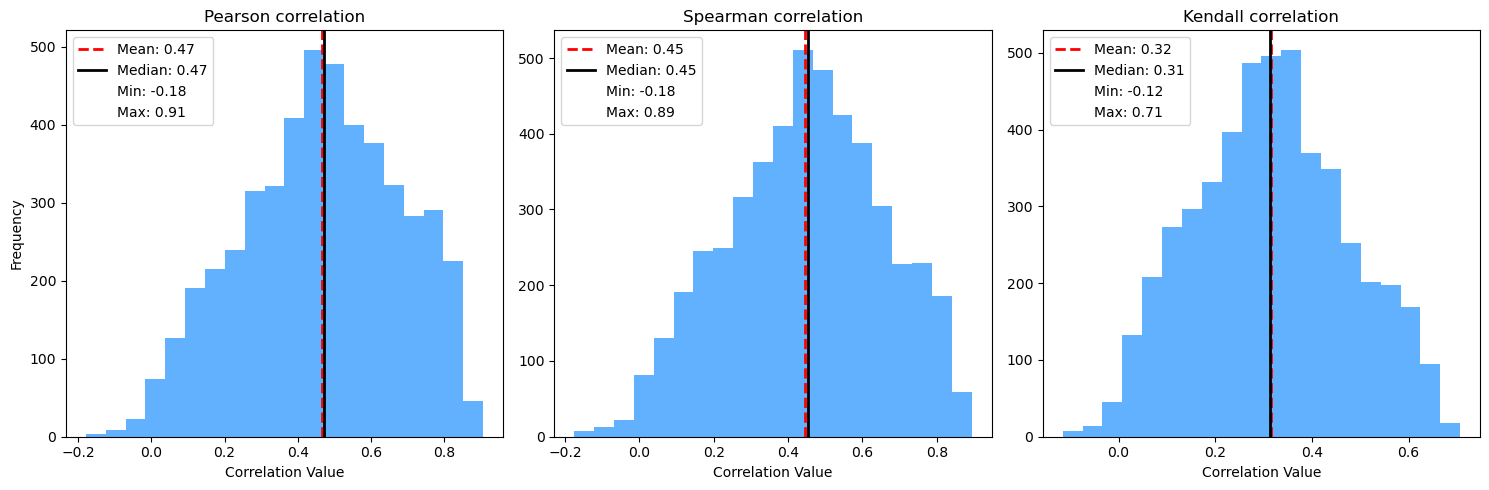

Pearson correlation - Min: -0.18, Max: 0.91
Spearman correlation - Min: -0.18, Max: 0.89
Kendall correlation - Min: -0.12, Max: 0.71


In [202]:
# Visualize distribution correlation plots

corr1 = pearson_correlations
corr2 = spearman_correlations
corr3 = kendall_correlations

# Calculate mean, median, min, and max for each measure
mean_corr1, median_corr1 = np.mean(corr1), np.median(corr1)
mean_corr2, median_corr2 = np.mean(corr2), np.median(corr2)
mean_corr3, median_corr3 = np.mean(corr3), np.median(corr3)

min_corr1, max_corr1 = np.min(corr1), np.max(corr1)
min_corr2, max_corr2 = np.min(corr2), np.max(corr2)
min_corr3, max_corr3 = np.min(corr3), np.max(corr3)

# Set up a figure with 3 subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot for Correlation 1
axes[0].hist(corr1, bins=20, color='dodgerblue', alpha=0.7)
axes[0].axvline(mean_corr1, color='r', linestyle='dashed', linewidth=2, label=f'Mean: {mean_corr1:.2f}')
axes[0].axvline(median_corr1, color='black', linestyle='solid', linewidth=2, label=f'Median: {median_corr1:.2f}')
axes[0].axvline(min_corr1, color='purple', linestyle='dotted', linewidth=2, label=f'Min: {min_corr1:.2f}', alpha=0)
axes[0].axvline(max_corr1, color='orange', linestyle='dotted', linewidth=2, label=f'Max: {max_corr1:.2f}', alpha=0)
axes[0].set_title('Pearson correlation')
axes[0].set_xlabel('Correlation Value')
axes[0].set_ylabel('Frequency')
axes[0].legend(loc='upper left')

# Plot for Correlation 2
axes[1].hist(corr2, bins=20, color='dodgerblue', alpha=0.7)
axes[1].axvline(mean_corr2, color='r', linestyle='dashed', linewidth=2, label=f'Mean: {mean_corr2:.2f}')
axes[1].axvline(median_corr2, color='black', linestyle='solid', linewidth=2, label=f'Median: {median_corr2:.2f}')
axes[1].axvline(min_corr2, color='purple', linestyle='dotted', linewidth=2, label=f'Min: {min_corr2:.2f}', alpha=0)
axes[1].axvline(max_corr2, color='orange', linestyle='dotted', linewidth=2, label=f'Max: {max_corr2:.2f}', alpha=0)
axes[1].set_title('Spearman correlation')
axes[1].set_xlabel('Correlation Value')
axes[1].legend(loc='upper left')

# Plot for Correlation 3
axes[2].hist(corr3, bins=20, color='dodgerblue', alpha=0.7)
axes[2].axvline(mean_corr3, color='r', linestyle='dashed', linewidth=2, label=f'Mean: {mean_corr3:.2f}')
axes[2].axvline(median_corr3, color='black', linestyle='solid', linewidth=2, label=f'Median: {median_corr3:.2f}')
axes[2].axvline(min_corr3, color='purple', linestyle='dotted', linewidth=2, label=f'Min: {min_corr3:.2f}', alpha=0)
axes[2].axvline(max_corr3, color='orange', linestyle='dotted', linewidth=2, label=f'Max: {max_corr3:.2f}', alpha=0)
axes[2].set_title('Kendall correlation')
axes[2].set_xlabel('Correlation Value')
axes[2].legend(loc='upper left')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plots
plt.show()

# Print min and max values for each correlation
print(f"Pearson correlation - Min: {min_corr1:.2f}, Max: {max_corr1:.2f}")
print(f"Spearman correlation - Min: {min_corr2:.2f}, Max: {max_corr2:.2f}")
print(f"Kendall correlation - Min: {min_corr3:.2f}, Max: {max_corr3:.2f}")


### Pearson regeression

In [203]:
# --- imports ---

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNet, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, spearmanr

# ---------------- helpers ----------------

def _align_and_prepare(proteomics, transcriptomics, protein_col, gene_col,
                       transform='log1p'):
    # align on proteomics index (drop missing later)
    y = proteomics.loc[proteomics.index, protein_col].astype(float)
    x = transcriptomics.loc[proteomics.index, gene_col].astype(float)

    ok = (~x.isna()) & (~y.isna())
    x, y = x[ok], y[ok]

    # ONLY apply log1p to x (as requested). No scaling anywhere.
    if transform == 'log1p':
        x = np.log1p(x)

    X = x.values.reshape(-1, 1)
    return X, y.values, x.index  # (n,1), (n,), cell index


def _stratify_bins(y, q=10):
    try:
        return pd.qcut(y, q=q, duplicates='drop')
    except Exception:
        return None


def _metrics(y_true, y_pred):
    if len(y_true) < 2:
        return {'pearson': np.nan, 'spearman': np.nan, 'rmse': np.nan, 'mae': np.nan, 'r2': np.nan}
    try:
        r, _ = pearsonr(y_true, y_pred)
    except Exception:
        r = np.nan
    try:
        sp = spearmanr(y_true, y_pred).correlation
    except Exception:
        sp = np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))
    r2   = float(r2_score(y_true, y_pred))
    return {'pearson': float(r), 'spearman': float(sp), 'rmse': rmse, 'mae': mae, 'r2': r2}


def _plot_pred_vs_obs(y_true, y_pred, out_png, title, show_plot=True):
    plt.figure()
    plt.scatter(y_true, y_pred, s=8, alpha=0.7)
    lo, hi = float(min(y_true.min(), y_pred.min())), float(max(y_true.max(), y_pred.max()))
    xs = np.linspace(lo, hi, 100)
    plt.plot(xs, xs, linewidth=1.0)
    plt.xlabel('Observed'); plt.ylabel('Predicted'); plt.title(title)
    plt.tight_layout()
    if out_png:
        plt.savefig(out_png, dpi=220)
    if show_plot:
        plt.show()
    plt.close()


# ---------------- main runner ----------------

def run_single_feature_elasticnet(
    proteomics, transcriptomics, protein_col, gene_col,
    test_size=0.1, random_state=42,
    transform='log1p',
    use_cv=True, alphas=(0.001), l1_ratios=(0.1, 0.5, 0.9),
    max_iter=1000, show_plot=True,
    out_pred_csv='single_feature_enet_predictions.csv',
    out_plot_png='single_feature_enet_pred_vs_obs.png'
):
    # 1) prep & split
    X, y, idx = _align_and_prepare(
        proteomics, transcriptomics, protein_col, gene_col, transform=transform
    )
    strat = _stratify_bins(y, q=10)
    X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
        X, y, idx, test_size=test_size, random_state=random_state, stratify=strat
    )

    # 2) model
    if use_cv:
        model = ElasticNetCV(
            alphas=None if alphas is None else np.asarray(alphas, dtype=float),
            l1_ratio=np.array(l1_ratios, dtype=float) if l1_ratios is not None else (0.1, 0.5, 0.9),
            cv=5, max_iter=max_iter, random_state=random_state
        )
    else:
        alpha = 1.0 if (alphas is None or (hasattr(alphas, '__len__') and len(alphas) == 0)) else float(alphas[0])
        l1 = float(l1_ratios[0]) if l1_ratios is not None else 0.5
        model = ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=max_iter, random_state=random_state)

    # keep a pipeline so named_steps['enet'] still works
    pipe = Pipeline([('enet', model)])

    # 3) fit & predict
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)

    # # 4) save + (optional) plot
    # pd.DataFrame({'cell_id': idx_te, 'y_true': y_te, 'y_pred': y_pred}).to_csv(out_pred_csv, index=False)
    # _plot_pred_vs_obs(
    #     y_te, y_pred,
    #     out_plot_png,
    #     title=f"{protein_col} ~ {gene_col} (ElasticNet, no scaling)",
    #     show_plot=show_plot
    # )

    # 5) metrics (+ chosen hyperparams if CV)
    m = _metrics(y_te, y_pred)
    m.update({'n_train': int(len(y_tr)), 'n_test': int(len(y_te))})
    enet = pipe.named_steps['enet']
    if isinstance(enet, ElasticNetCV):
        m.update({'alpha_': float(enet.alpha_), 'l1_ratio_': float(enet.l1_ratio_)})
    return m



In [204]:
# pe85 is iterable 
all_metrics = []
for prot in pe85:
    metrics = run_single_feature_elasticnet(
        proteomics, transcriptomics,
        protein_col=prot, gene_col=prot,
        test_size=0.2, random_state=42,
        transform='log1p',             # <-- only log1p(X)
        use_cv=True,
        alphas=(0.001,),                   # let ENetCV choose
        l1_ratios=(0.1, 0.5, 0.9),
        show_plot=False,               # suppress plots in the loop
        out_pred_csv=f'pred_{prot}.csv',
        out_plot_png=f'pred_vs_obs_{prot}.png'
    )
    metrics['protein'] = prot
    all_metrics.append(metrics)

metrics_df = pd.DataFrame(all_metrics).set_index('protein').sort_index()
display(metrics_df)              # in notebooks
#metrics_df.to_csv('single_feature_enet_metrics_table.csv')

,pearson,spearman,rmse,mae,r2,n_train,n_test,alpha_,l1_ratio_
protein,,,,,,,,,
ALDH1A1,0.844215,0.735935,0.909330,0.702846,0.710986,276,69,0.001,0.1
ALDH1A3,0.783182,0.864795,1.124709,0.947910,0.611565,276,69,0.001,0.1
ALDH2,0.822484,0.858312,0.872807,0.694369,0.674702,276,69,0.001,0.1
ANPEP,0.837182,0.697386,0.948388,0.735860,0.696613,276,69,0.001,0.1
BASP1,0.864985,0.839607,1.262513,0.980463,0.747805,276,69,0.001,0.9
CA2,0.820163,0.852453,1.110795,0.831527,0.671273,276,69,0.001,0.9
CD44,0.843754,0.860504,0.801717,0.672236,0.711195,276,69,0.001,0.1
CDCP1,0.864780,0.852873,0.731646,0.581261,0.747386,276,69,0.001,0.9
CDH1,0.858347,0.868188,0.944148,0.752780,0.728420,276,69,0.001,0.9


In [218]:
# Cell A — compact helpers + incremental (LinearRegression) + test prep

# ---- helpers ----
def _metrics(y_true, y_pred):
    if len(y_true) < 2:
        return {'pearson': np.nan, 'spearman': np.nan, 'rmse': np.nan, 'mae': np.nan, 'r2': np.nan}
    try: r, _ = pearsonr(y_true, y_pred)
    except Exception: r = np.nan
    try: sp = spearmanr(y_true, y_pred).correlation
    except Exception: sp = np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))
    r2   = float(r2_score(y_true, y_pred))
    return {'pearson': float(r), 'spearman': float(sp), 'rmse': rmse, 'mae': mae, 'r2': r2}

def _stratify_bins(y, q=10):
    try: return pd.qcut(y, q=q, duplicates='drop')
    except Exception: return None

def _get_sorted_genes_by_corr(pearson_df, protein, use_abs=True, dropna=True):
    s = pearson_df.loc[protein]
    if dropna: s = s.dropna()
    return s.reindex(s.abs().sort_values(ascending=False).index) if use_abs else s.sort_values(ascending=False)

def _prepare_xy_multi(proteomics, transcriptomics, protein, genes, transform='log1p'):
    genes = [g for g in genes if g in transcriptomics.columns]
    if not genes: raise ValueError("No genes present in transcriptomics for selection.")
    y = proteomics.loc[proteomics.index, protein].astype(float)
    X = transcriptomics.loc[proteomics.index, genes].astype(float)
    if transform == 'log1p': X = np.log1p(X)
    df = pd.concat([y.rename("__y__"), X], axis=1).dropna(axis=0)
    y = df.pop("__y__").values; X = df.values
    if X.shape[0] > 1:
        var = X.var(axis=0); keep = var > 0
        X = X[:, keep]; kept_genes = list(df.columns[keep])
    else:
        kept_genes = list(df.columns)
    return X, y, kept_genes

def _prepare_test_Xy(prot_test, transcriptomics_like, protein, genes, transform='log1p'):
    genes = [g for g in genes if g in transcriptomics_like.columns]
    if not genes: return None, None, [], pd.Index([])
    y_te = prot_test.loc[prot_test.index, protein].astype(float)
    X_te = transcriptomics_like.loc[prot_test.index, genes].astype(float)
    if transform == 'log1p': X_te = np.log1p(X_te)
    df_te = pd.concat([y_te.rename('__y__'), X_te], axis=1).dropna(axis=0)
    if df_te.empty: return None, None, [], pd.Index([])
    y_out = df_te.pop('__y__').values; X_out = df_te.values
    return X_out, y_out, list(df_te.columns), df_te.index

# ---- incremental forward selection (LinearRegression) ----
def run_incremental_until_mae(
    proteomics, transcriptomics, pearson_df, protein,
    mae_threshold=0.2,                  # fixed target (if set, schedule below ignored)
    threshold_start=None, threshold_end=None, threshold_schedule='geometric',
    max_features=200,
    min_improve_rel=0.0, min_improve_abs=0.0, patience=300,
    use_abs_corr=True, transform='log1p', test_size=0.2, random_state=42
):
    ranked = _get_sorted_genes_by_corr(pearson_df, protein, use_abs=use_abs_corr)
    ranked = [g for g in ranked.index if g in transcriptomics.columns]
    if not ranked: raise ValueError("No overlapping genes between pearson table and transcriptomics columns.")

    def _threshold_at(k):
        if mae_threshold is not None: return float(mae_threshold)
        if threshold_start is None and threshold_end is None: return np.inf
        if threshold_schedule == 'linear':
            if threshold_start is None or threshold_end is None: raise ValueError("linear schedule needs start and end")
            return float(threshold_start + (threshold_end - threshold_start) * ((k-1)/max(1,(max_features-1))))
        if threshold_start is None or threshold_end is None:
            return float(threshold_start * (0.95 ** (k-1))) if threshold_start is not None else np.inf
        factor = (threshold_end/threshold_start) ** (1.0/max(1,(max_features-1)))
        return float(threshold_start * (factor ** (k-1)))

    history, selected = [], []
    best_mae, no_improve = np.inf, 0
    final_model = None; final_metrics = None

    for g in ranked:
        cand = selected + [g]
        try:
            X, y, kept = _prepare_xy_multi(proteomics, transcriptomics, protein, cand, transform=transform)
        except ValueError:
            continue
        if X.shape[0] < 5: continue
        cand = [gg for gg in kept if gg in cand]
        if not cand: continue

        strat = _stratify_bins(y, q=10)
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=strat)
        model = LinearRegression().fit(X_tr, y_tr)
        m = _metrics(y_te, model.predict(X_te))

        k = len(cand); thr = _threshold_at(k)
        rel_ok = (m['mae'] <= best_mae * (1 - min_improve_rel)) if min_improve_rel > 0 else True
        abs_ok = (m['mae'] <= best_mae - min_improve_abs) if min_improve_abs > 0 else True
        improved = (m['mae'] < best_mae) and rel_ok and abs_ok

        if improved or best_mae == np.inf:
            selected, best_mae = cand, m['mae']
            no_improve = 0; final_model = model; final_metrics = m
            accepted = True
        else:
            accepted = False; no_improve += 1

        history.append({
            'k': k, 'threshold': thr, 'accepted': accepted,
            'mae': m['mae'], 'rmse': m['rmse'], 'r2': m['r2'],
            'pearson': m['pearson'], 'spearman': m['spearman'],
            'n_train': len(y_tr), 'n_test': len(y_te),
            'genes_candidate': tuple(cand), 'genes_selected': tuple(selected)
        })

        if best_mae <= thr or len(selected) >= max_features or (patience is not None and no_improve >= patience):
            break

    history_df = pd.DataFrame(history)
    return {
        'protein': protein,
        'history_df': history_df,
        'final_genes': list(history_df.iloc[-1]['genes_selected']) if len(history_df) else [],
        'final_metrics': final_metrics,
        'model': final_model
    }


In [206]:
# top n enet

def run_elasticnet_topn(
    proteomics, transcriptomics, pearson_df, protein,
    top_n=200,
    use_abs_corr=True,             # rank by |corr|
    transform='log1p',             # ONLY applied to X
    test_size=0.2, random_state=42,
    alphas=(0.001),                   # None -> ENetCV default grid
    l1_ratios=(0.1, 0.5, 0.9),
    max_iter=10000, cv=5
):
    """
    Select the top-N genes by Pearson correlation (per protein) and fit ElasticNetCV.
    No scaling; only optional log1p on X. Returns metrics and best hyperparams.
    """
    ranked = _get_sorted_genes_by_corr(pearson_df, protein, use_abs=use_abs_corr)
    ranked = [g for g in ranked.index if g in transcriptomics.columns]
    if len(ranked) == 0:
        raise ValueError("No overlapping genes between pearson table and transcriptomics columns.")

    genes = ranked[:top_n]
    X, y, kept_genes = _prepare_xy_multi(proteomics, transcriptomics, protein, genes, transform=transform)
    if X.shape[0] < 5:
        raise ValueError("Too few usable samples after filtering.")

    # split & fit
    strat = _stratify_bins(y, q=10)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=strat
    )

    enet = ElasticNetCV(
        alphas=None if alphas is None else np.asarray(alphas, dtype=float),
        l1_ratio=np.array(l1_ratios, dtype=float) if l1_ratios is not None else (0.1, 0.5, 0.9),
        cv=cv, max_iter=max_iter, random_state=random_state
    )
    enet.fit(X_tr, y_tr)
    y_pred = enet.predict(X_te)
    m = _metrics(y_te, y_pred)

    return {
        'protein': protein,
        'genes': kept_genes,        # after constant-col drop
        'n_features': len(kept_genes),
        'metrics': m,
        'alpha_': float(enet.alpha_),
        'l1_ratio_': float(enet.l1_ratio_)
    }


In [ ]:
# trial of two pe pipelines only one protein

PROTEIN = "VIL1"        # ← change this
MAE_THRESHOLD = 0.15     # stop condition for incremental
TOP_N = 25               # number of features for ElasticNetCV

# 1) Incremental LinearRegression until MAE <= threshold
res_inc = run_incremental_until_mae(
    proteomics, transcriptomics, pearson,
    protein=PROTEIN,
    mae_threshold=MAE_THRESHOLD,
    max_features=200,
    use_abs_corr=True,
    transform='log1p',
    test_size=0.2, random_state=42
)
print(f"[Incremental] protein={res_inc['protein']}")
display(res_inc['history_df'])
print("Final genes:", res_inc['final_genes'])
print("Final metrics:", res_inc['final_metrics'])

# 2) ElasticNetCV on top-N Pearson genes
res_enet = run_elasticnet_topn(
    proteomics, transcriptomics, pearson,
    protein=PROTEIN,
    top_n=TOP_N,
    use_abs_corr=True,
    transform='log1p',
    test_size=0.2, random_state=42,
    alphas=None, l1_ratios=(0.1, 0.5, 0.9), max_iter=1000, cv=5
)
print(f"\n[ElasticNetCV-Top{TOP_N}] protein={res_enet['protein']}")
print("Used genes (after constant drop):", res_enet['genes'])
print("n_features:", res_enet['n_features'])
print("alpha_:", res_enet['alpha_'], "l1_ratio_:", res_enet['l1_ratio_'])
print("metrics:", res_enet['metrics'])


[Incremental] protein=VIL1


,k,threshold,accepted,mae,rmse,r2,pearson,spearman,n_train,n_test,genes_candidate,genes_selected
0,1,0.15,True,0.538232,0.724055,0.790278,0.890512,0.409245,276,69,"(VIL1,)","(VIL1,)"
1,2,0.15,True,0.538038,0.719579,0.792863,0.891550,0.413709,276,69,"(VIL1, HNF4A)","(VIL1, HNF4A)"
2,3,0.15,False,0.545572,0.728406,0.787750,0.888056,0.391524,276,69,"(VIL1, HNF4A, EPS8L3)","(VIL1, HNF4A)"
3,3,0.15,True,0.529612,0.685079,0.812249,0.901275,0.419547,276,69,"(VIL1, HNF4A, CLRN3)","(VIL1, HNF4A, CLRN3)"
4,4,0.15,True,0.527707,0.677709,0.816267,0.903476,0.414176,276,69,"(VIL1, HNF4A, CLRN3, MIR194-2HG)","(VIL1, HNF4A, CLRN3, MIR194-2HG)"
...,...,...,...,...,...,...,...,...,...,...,...,...
1871,189,0.15,False,0.223339,0.368262,0.945748,0.973228,0.807600,276,69,"(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,...","(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,..."
1872,189,0.15,False,0.313835,0.435962,0.923968,0.961424,0.781403,276,69,"(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,...","(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,..."
1873,189,0.15,False,0.386068,0.526106,0.889274,0.943507,0.646620,276,69,"(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,...","(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,..."
1874,189,0.15,False,0.283348,0.410215,0.932683,0.965994,0.780161,276,69,"(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,...","(VIL1, HNF4A, CLRN3, MIR194-2HG, MUC13, PRAP1,..."


Final genes: ['VIL1', 'HNF4A', 'CLRN3', 'MIR194-2HG', 'MUC13', 'PRAP1', 'ZNF511-PRAP1', 'FOXA3', 'GPR35', 'CCL15', 'MYO1A', 'TRIM15', 'SLC39A5', 'BCL2L14', 'IHH', 'LINC00543', 'CCL15-CCL14', 'GUCY2C', 'PDZD3', 'PDX1', 'A1CF', 'AC020656.2', 'REG4', 'ANXA13', 'TMEM238L', 'FUT2', 'APOBEC1', 'NOX1', 'BNIP5', 'RNF43', 'NOXO1', 'BCL2L15', 'DPEP1', 'PRR26', 'IYD', 'TRIM31', 'CIDEC', 'AC009065.2', 'AC097639.1', 'AC026462.3', 'AC021218.1', 'SGK2', 'CTSE', 'GPX2', 'LRRC31', 'TMPRSS2', 'CYP2B6', 'TMEM45B', 'DLL4', 'GUCA2A', 'HSD11B2', 'MYRF', 'AL390719.2', 'PCK1', 'GMDS', 'AC009065.5', 'AGR3', 'GNB4', 'TMEM176A', 'SMIM6', 'C2orf72', 'IL20RA', 'AC007620.2', 'CCL24', 'AC010503.5', 'AP001107.9', 'PROX1', 'PRR15', 'TESC', 'AC005280.1', 'MYO7B', 'RDX', 'KDM7A', 'FOXQ1', 'ADH6', 'TM4SF4', 'DNAJC22', 'AC104958.2', 'A1BG-AS1', 'GATA6', 'IL17RE', 'MISP', 'HHLA2', 'PPP1R18', 'FAM47E', 'AIFM3', 'ZSWIM5', 'TUSC8', 'CHST10', 'ELOVL5', 'STARD10', 'DENND5A', 'ADAP1', 'TMEM141', 'C4BPB', 'SCPEP1', 'MYO1D', 'A1BG

c:\Users\hp\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1641: FutureWarning: 'alphas=None' is deprecated and will be removed in 1.9, at which point the default value will be set to 100. Set 'alphas=100' to silence this warning.
  warnings.warn(


In [213]:
# run incremental (LinearRegression) for a list of proteins `pe85` 
# on training to find best genes for each protein
# and collect only the final/best metrics row per protein into a summary df.

PROTEIN_LIST    = pe85            # list of proteins
MAE_THRESHOLD   = 0.15         # stop condition for incremental
MAX_FEATURES    = 500
TEST_SIZE       = 0.20
RANDOM_STATE    = 42
USE_ABS_CORR    = True
TRANSFORM       = 'log1p'

rows = []
for prot in PROTEIN_LIST:
    try:
        res = run_incremental_until_mae(
            proteomics, transcriptomics, pearson,
            protein=prot,
            mae_threshold=MAE_THRESHOLD,
            max_features=MAX_FEATURES,
            use_abs_corr=USE_ABS_CORR,
            transform=TRANSFORM,
            patience= 200,
            test_size=TEST_SIZE, random_state=RANDOM_STATE
        )

        hist = res.get('history_df', None)
        if isinstance(hist, pd.DataFrame) and len(hist):
            last = hist.iloc[-1]                   # final (best) step
            m = res.get('final_metrics', {}) or {} # metrics from the final accepted model

            rows.append({
                'protein': prot,
                'k_features': int(len(res.get('final_genes', []))),
                'k_best': int(m.get('k_best', len(res.get('final_genes', [])))),  # may not be present; fallback
                'mae': float(m.get('mae', np.nan)),
                'rmse': float(m.get('rmse', np.nan)),
                'r2': float(m.get('r2', np.nan)),
                'pearson': float(m.get('pearson', np.nan)),
                'spearman': float(m.get('spearman', np.nan)),
                'genes': ';'.join(res.get('final_genes', [])),
                'accepted_last_step': bool(last.get('accepted', True)),
                'status': 'ok'
            })
            print(f'✅ {prot}: k={len(res.get("final_genes", []))}, MAE={m.get("mae", np.nan)}')
        else:
            rows.append({'protein': prot, 'status': 'no_valid_model'})
            print(f'⚠️ {prot}: no valid model')

    except Exception as e:
        rows.append({'protein': prot, 'status': f'error: {e}'})
        print(f'❌ {prot}: {e}')

summary_df = pd.DataFrame(rows)

# Ensure expected columns exist and order them (no ElasticNetCV params here)
col_order = [
    'protein','k_features','k_best','mae','rmse','r2','pearson','spearman',
    'accepted_last_step','genes','status'
]
for c in col_order:
    if c not in summary_df.columns:
        summary_df[c] = np.nan

summary_df['mae'] = pd.to_numeric(summary_df['mae'], errors='coerce')
summary_df = summary_df.reindex(columns=col_order)
summary_df = summary_df.sort_values(by='mae', na_position='last').reset_index(drop=True)

display(summary_df)
# summary_df.to_csv('incremental_summary_p85.csv', index=False)


✅ VIM: k=181, MAE=0.2658210621063967
✅ VIL1: k=188, MAE=0.21693543599825085
✅ TRIP6: k=210, MAE=0.25277151706296186
✅ TJP2: k=207, MAE=0.14962533490662958
✅ TGM2: k=225, MAE=0.26643589078286367
✅ ST14: k=218, MAE=0.2908021570279205
✅ SPATS2L: k=209, MAE=0.2138484765945639
✅ SLC16A3: k=197, MAE=0.21862844937668832
✅ SERPINH1: k=210, MAE=0.18060833547620922
✅ SERPINB5: k=241, MAE=0.2330561349168572
✅ SELENBP1: k=205, MAE=0.21516328430508408
✅ RBM47: k=202, MAE=0.23808829628224207
✅ PTK7: k=164, MAE=0.19049390889206802
✅ PSMB8: k=186, MAE=0.1486569162328396
✅ PDLIM4: k=229, MAE=0.2310229588805212
✅ PDLIM1: k=237, MAE=0.17256667472819046
✅ PAPSS2: k=208, MAE=0.21940601165860235
✅ NT5E: k=208, MAE=0.2740011300064483
✅ MYO1D: k=196, MAE=0.21639299064656384
✅ MCAM: k=221, MAE=0.2593578883582127
✅ MAP1B: k=213, MAE=0.2601820233738339
✅ MAGEA4: k=194, MAE=0.2628744902865799
✅ LGALS1: k=209, MAE=0.15034209543063226
✅ LCP1: k=202, MAE=0.29862146734691636
✅ LAD1: k=187, MAE=0.23668516107659193
✅ I

,protein,k_features,k_best,mae,rmse,r2,pearson,spearman,accepted_last_step,genes,status
0,PSMB8,186,186,0.148657,0.237039,0.951411,0.975456,0.974680,True,PSMB8;PSMB8-AS1;HLA-B;APOL6;TAP1;NLRC5;B2M;HLA...,ok
1,TJP2,207,207,0.149625,0.224135,0.964950,0.982343,0.985934,True,TJP2;TINAGL1;EPS8L2;KRT19;NIPAL1;CLDN4;CRB3;AN...,ok
2,LGALS1,209,209,0.150342,0.243011,0.974360,0.988224,0.984728,False,LGALS1;EMP3;ANXA5;HSD11B2;VIM-AS1;AXL;C2orf15;...,ok
3,CKAP4,181,181,0.170526,0.291101,0.934277,0.966794,0.960395,False,CKAP4;CFL2;GPX8;AC004687.1;BTK;KLHL6;NCF4;SPI1...,ok
4,PDLIM1,237,237,0.172567,0.284674,0.953706,0.978391,0.972525,False,PDLIM1;AC109322.1;IRF1;DLGAP1;VSIR;EFR3B;CERS1...,ok
5,ERBB2,219,219,0.173228,0.293891,0.943782,0.972785,0.951662,False,ERBB2;KIAA1522;MIEN1;C6orf132;CTNND1;RHBDF1;GI...,ok
6,ITGA2,214,214,0.178056,0.299084,0.962098,0.984555,0.988856,False,ITGA2;GPR39;LAMC2;F3;CDCP1;S100A16;ARL14;MYOF;...,ok
7,SERPINH1,210,210,0.180608,0.295057,0.929305,0.964580,0.957106,False,SERPINH1;GPX8;CAVIN1;AMOTL2;ARHGEF17;LAMB2;FST...,ok
8,DPYSL3,225,225,0.188465,0.294062,0.966552,0.984932,0.980270,False,DPYSL3;TMC6;CDH2;DPYSL2;KIAA0408;PTX3;VCAN;C8o...,ok
9,PTK7,164,164,0.190494,0.299033,0.946198,0.972803,0.964377,False,PTK7;FBLN1;SIX4;EFNB3;NTF4;BCAM;S1PR5;IL17RD;T...,ok


In [ ]:
# Cell B — run training (incremental selection) + final testing on prot_test, end-to-end


# -------- config (edit here) --------
PROTEIN_LIST  = pe85          # list variable, e.g. pe85
MAE_THRESHOLD = 0.15
MAX_FEATURES  = 300
TEST_SIZE     = 0.20
RANDOM_STATE  = 42
USE_ABS_CORR  = True
TRANSFORM     = 'log1p'
# OUT_SUMMARY_CSV = 'incremental_summary.csv'
# OUT_TEST_CSV    = 'incremental_test_summary.csv'
# -----------------------------------

# ensure transcriptomics_test exists for prot_test
if 'transcriptomics_test' not in globals():
    transcriptomics_test = transcriptomics.loc[prot_test.index].copy()

# ---- TRAIN: incremental per protein -> summary_df ----
rows = []
for prot in PROTEIN_LIST:
    try:
        res = run_incremental_until_mae(
            proteomics, transcriptomics, pearson,
            protein=prot, mae_threshold=MAE_THRESHOLD,
            max_features=MAX_FEATURES, use_abs_corr=USE_ABS_CORR,
            transform=TRANSFORM, test_size=TEST_SIZE, random_state=RANDOM_STATE
        )
        hist = res['history_df']
        if isinstance(hist, pd.DataFrame) and len(hist):
            last = hist.iloc[-1]; m = res.get('final_metrics', {}) or {}
            rows.append({
                'protein': prot,
                'k_features': int(len(res.get('final_genes', []))),
                'mae': float(m.get('mae', np.nan)),
                'rmse': float(m.get('rmse', np.nan)),
                'r2': float(m.get('r2', np.nan)),
                'pearson': float(m.get('pearson', np.nan)),
                'spearman': float(m.get('spearman', np.nan)),
                'accepted_last_step': bool(last.get('accepted', True)),
                'genes': ';'.join(res.get('final_genes', [])),
                'status': 'ok'
            })
        else:
            rows.append({'protein': prot, 'status': 'no_valid_model'})
    except Exception as e:
        rows.append({'protein': prot, 'status': f'error: {e}'})

summary_df = pd.DataFrame(rows)
col_order = ['protein','k_features','mae','rmse','r2','pearson','spearman','accepted_last_step','genes','status']
for c in col_order:
    if c not in summary_df.columns: summary_df[c] = np.nan
summary_df['mae'] = pd.to_numeric(summary_df['mae'], errors='coerce')
summary_df = summary_df.reindex(columns=col_order).sort_values(by='mae', na_position='last').reset_index(drop=True)
display(summary_df)
# summary_df.to_csv(OUT_SUMMARY_CSV, index=False)

# ---- TEST: retrain on full TRAIN with chosen genes; evaluate on prot_test ----
test_rows = []
for _, row in summary_df.iterrows():
    prot = row['protein']; genes_str = row.get('genes', '')
    if pd.isna(prot) or not isinstance(genes_str, str) or not genes_str.strip():
        test_rows.append({'protein': prot, 'status': 'no_genes'}); continue
    genes = [g for g in genes_str.split(';') if g]
    try:
        X_tr, y_tr, kept = _prepare_xy_multi(proteomics, transcriptomics, prot, genes, transform=TRANSFORM)
        if X_tr is None or X_tr.shape[0] < 2 or not kept:
            test_rows.append({'protein': prot, 'status': 'no_train_data'}); continue
        model = LinearRegression().fit(X_tr, y_tr)

        X_te, y_te, used, kept_idx = _prepare_test_Xy(prot_test, transcriptomics_test, prot, kept, transform=TRANSFORM)
        if X_te is None or len(y_te) < 1:
            test_rows.append({'protein': prot, 'status': 'no_test_data'}); continue

        m = _metrics(y_te, model.predict(X_te))
        test_rows.append({
            'protein': prot, 'k_features': len(used),
            'mae': m['mae'], 'rmse': m['rmse'], 'r2': m['r2'],
            'pearson': m['pearson'], 'spearman': m['spearman'],
            'n_test': int(len(y_te)), 'genes': ';'.join(used), 'status': 'ok'
        })
    except Exception as e:
        test_rows.append({'protein': prot, 'status': f'error: {e}'})

test_summary_df = pd.DataFrame(test_rows)
test_cols = ['protein','k_features','mae','rmse','r2','pearson','spearman','n_test','genes','status']
for c in test_cols:
    if c not in test_summary_df.columns: test_summary_df[c] = np.nan
test_summary_df['mae'] = pd.to_numeric(test_summary_df['mae'], errors='coerce')
test_summary_df = test_summary_df.reindex(columns=test_cols).sort_values(by='mae', na_position='last').reset_index(drop=True)

display(test_summary_df)
# test_summary_df.to_csv(OUT_TEST_CSV, index=False)


,protein,k_features,mae,rmse,r2,pearson,spearman,accepted_last_step,genes,status
0,PSMB8,220,0.124706,0.209237,0.962141,0.981162,0.979430,False,PSMB8;PSMB8-AS1;HLA-B;APOL6;TAP1;NLRC5;B2M;HLA...,ok
1,TJP2,234,0.133391,0.216524,0.967290,0.983542,0.987358,False,TJP2;TINAGL1;EPS8L2;KRT19;NIPAL1;CLDN4;CRB3;AN...,ok
2,PTK7,224,0.143278,0.274219,0.954757,0.977324,0.967629,False,PTK7;FBLN1;SIX4;EFNB3;NTF4;BCAM;S1PR5;IL17RD;T...,ok
3,LGALS1,221,0.144180,0.233083,0.976412,0.989391,0.985020,False,LGALS1;EMP3;ANXA5;HSD11B2;VIM-AS1;AXL;C2orf15;...,ok
4,CKAP4,212,0.155321,0.274020,0.941764,0.970701,0.967702,False,CKAP4;CFL2;GPX8;AC004687.1;BTK;KLHL6;NCF4;SPI1...,ok
5,ITGA2,236,0.161420,0.285611,0.965435,0.986038,0.989697,False,ITGA2;GPR39;LAMC2;F3;CDCP1;S100A16;ARL14;MYOF;...,ok
6,ERBB2,224,0.169904,0.292352,0.944370,0.972819,0.951845,False,ERBB2;KIAA1522;MIEN1;C6orf132;CTNND1;RHBDF1;GI...,ok
7,SERPINH1,234,0.170801,0.291154,0.931163,0.965773,0.958933,False,SERPINH1;GPX8;CAVIN1;AMOTL2;ARHGEF17;LAMB2;FST...,ok
8,PDLIM1,237,0.172567,0.284674,0.953706,0.978391,0.972525,False,PDLIM1;AC109322.1;IRF1;DLGAP1;VSIR;EFR3B;CERS1...,ok
9,DPYSL3,233,0.175256,0.260888,0.973673,0.987444,0.985824,False,DPYSL3;TMC6;CDH2;DPYSL2;KIAA0408;PTX3;VCAN;C8o...,ok


,protein,k_features,mae,rmse,r2,pearson,spearman,n_test,genes,status
0,GNG12,220,0.569090,0.692561,0.862229,0.948986,0.706957,24,GNG12;WAS;AC004687.1;TNFRSF12A;CD53;NCKAP1L;RH...,ok
1,MYO1D,227,0.570977,0.677041,0.640063,0.846887,0.732174,24,MYO1D;ERBB3;LAD1;BICDL2;C1orf210;FXYD3;EPCAM;O...,ok
2,PDLIM1,237,0.591239,0.806129,0.596407,0.793423,0.738261,24,PDLIM1;AC109322.1;IRF1;DLGAP1;VSIR;EFR3B;CERS1...,ok
3,DAB2,256,0.605314,0.759878,0.680804,0.845413,0.853043,24,DAB2;NNMT;MAGI2-AS3;SERPINE2;CDH2;CALU;DLC1;GN...,ok
4,TJP2,234,0.607464,0.745301,0.427841,0.723621,0.806087,24,TJP2;TINAGL1;EPS8L2;KRT19;NIPAL1;CLDN4;CRB3;AN...,ok
5,IGF2BP1,242,0.615758,0.742910,0.778815,0.889166,0.793043,24,IGF2BP1;AC091133.5;AC091133.3;P4HTM;ARID3A;TRI...,ok
6,MAP1B,220,0.620113,0.798232,0.722854,0.852167,0.857391,24,MAP1B;DCLK2;TMC6;DPYSL3;CHN1;GPR176;LARP6;SGCB...,ok
7,ERBB2,224,0.635267,0.876518,0.571745,0.829431,0.648696,24,ERBB2;KIAA1522;MIEN1;C6orf132;CTNND1;RHBDF1;GI...,ok
8,PSMB8,220,0.648330,0.887177,0.238507,0.672822,0.687826,24,PSMB8;PSMB8-AS1;HLA-B;APOL6;TAP1;NLRC5;B2M;HLA...,ok
9,RBM47,208,0.650777,0.813849,0.645652,0.849365,0.805217,24,RBM47;ELF3;MISP;EPS8L2;SPINT1-AS1;TMC4;FRK;KDF...,ok


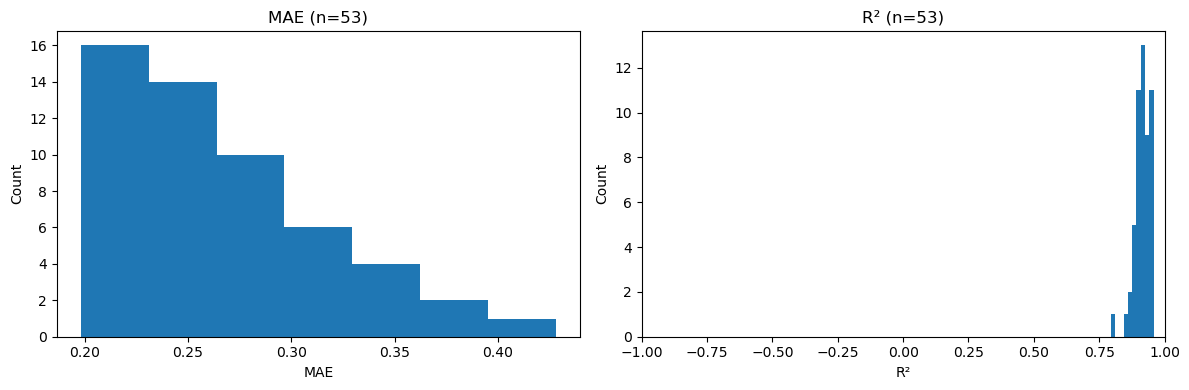

In [216]:
#histograms for MAE and R²
# Safely extract numeric series
mae = pd.to_numeric(summary_df.get('mae', pd.Series(dtype=float)), errors='coerce').dropna()
r2  = pd.to_numeric(summary_df.get('r2',  pd.Series(dtype=float)), errors='coerce').dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# MAE histogram
if len(mae):
    axes[0].hist(mae, bins='auto')
    axes[0].set_title(f"MAE (n={len(mae)})")
    axes[0].set_xlabel("MAE")
    axes[0].set_ylabel("Count")
else:
    axes[0].text(0.5, 0.5, "No MAE data", ha="center", va="center")
    axes[0].axis("off")

# R² histogram
if len(r2):
    axes[1].hist(r2, bins='auto')
    axes[1].set_title(f"R² (n={len(r2)})")
    axes[1].set_xlabel("R²")
    axes[1].set_ylabel("Count")
    axes[1].set_xlim(-1, 1)
else:
    axes[1].text(0.5, 0.5, "No R² data", ha="center", va="center")
    axes[1].axis("off")

plt.tight_layout()
plt.show()